# 01 · Why NumPy Exists

**Module 02 — NumPy & Numerical Computing**

---

## What you will learn

1. Why a Python list of numbers is slow — the answer is **memory layout**, not interpreter speed alone.
2. What "vectorised" actually means underneath, and why it is not just "a loop someone else wrote".
3. How to measure the difference yourself rather than take it on faith.
4. Universal functions (ufuncs) — the interface every NumPy operation shares.
5. When NumPy is *not* the right answer.

**Estimated time:** 60 minutes

> Module 01 promised that `arr.sum()` is dramatically faster than `sum(my_list)`,
> and that `sys.getsizeof` lies about containers. This notebook settles both.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np

from dstoolkit import format_bytes, setup_plot_style
from dstoolkit.plotting import COLORS

setup_plot_style()

print(f"NumPy version : {np.__version__}")

NumPy version : 2.5.1


## 1. The problem with a list of numbers

A Python `list` is a fantastic general-purpose container. It holds anything, in
any mix, and grows on demand. That flexibility has a cost, and the cost is
structural.

![Why NumPy is faster: memory layout](../../../assets/images/numpy_memory_layout.png)

A list does not store your numbers. It stores **pointers** to full Python
objects that live elsewhere in memory. Adding two lists element-wise therefore
means, for every single element:

1. follow a pointer to object A,
2. follow a pointer to object B,
3. check both types at runtime,
4. dispatch to the right `__add__`,
5. allocate a *new* Python object for the result,
6. store a pointer to it.

An ndarray stores the raw numbers, back to back, all of one type. Adding two
arrays runs a tight loop in compiled C with none of steps 1–4.

### Seeing the overhead

In [2]:
py_int = 10
np_int = np.int64(10)

print(f"a Python int object : {sys.getsizeof(py_int)} bytes")
print(f"one int64 in an array : 8 bytes")
print(f"\n→ roughly {sys.getsizeof(py_int) / 8:.0f}× the storage, "
      f"for the same number")

a Python int object : 28 bytes
one int64 in an array : 8 bytes

→ roughly 4× the storage, for the same number


> [!NOTE]
> Those extra bytes are not waste — they are the reference count, the type
> pointer, and the arbitrary-precision digits that make Python integers
> unbounded (Module 01, notebook 02). You are paying for genuine features. The
> point is that in numerical work you rarely need them, and NumPy lets you
> decline.

### `sys.getsizeof` lies about containers

Module 01 flagged this: `getsizeof` is **shallow**. For a list it counts the
array of pointers and nothing they point to.

In [3]:
n = 1_000_000
py_list = list(range(n))
np_array = np.arange(n, dtype=np.int64)

shallow = sys.getsizeof(py_list)
# The honest figure: the pointer array PLUS every object it references.
true_size = shallow + sum(sys.getsizeof(x) for x in py_list)

print(f"list, as getsizeof reports it : {format_bytes(shallow):>12}")
print(f"list, counting the objects too: {format_bytes(true_size):>12}   ← the truth")
print(f"ndarray, .nbytes              : {format_bytes(np_array.nbytes):>12}")
print(f"\n→ the array uses {true_size / np_array.nbytes:.1f}× less memory")

list, as getsizeof reports it :      7.6 MiB
list, counting the objects too:     34.3 MiB   ← the truth
ndarray, .nbytes              :      7.6 MiB

→ the array uses 4.5× less memory


`ndarray.nbytes` is exact and needs no caveat, because there is nothing else to
count — the data *is* the buffer.

In [4]:
print(f"{np_array.size} elements × {np_array.itemsize} bytes = "
      f"{np_array.nbytes:,} bytes")
print(f"nbytes == size × itemsize : "
      f"{np_array.nbytes == np_array.size * np_array.itemsize}")

1000000 elements × 8 bytes = 8,000,000 bytes
nbytes == size × itemsize : True


## 2. Measuring the speed difference

Let us settle the claim from Module 01 with a measurement rather than an
assertion. Four ways to sum a million numbers:

In [5]:
def time_it(fn, *args, repeats: int = 3) -> float:
    """Return the best of `repeats` timings, in seconds.

    We take the MINIMUM, not the mean. Timing noise is one-sided — background
    processes can only ever make a run slower, never faster — so the fastest
    observed run is the closest estimate of the true cost.
    """
    best = float("inf")
    for _ in range(repeats):
        start = time.perf_counter()
        fn(*args)
        best = min(best, time.perf_counter() - start)
    return best


def python_loop(values) -> float:
    total = 0
    for v in values:
        total += v
    return total


approaches = {
    "for loop over a list": (python_loop, py_list),
    "built-in sum() on a list": (sum, py_list),
    "built-in sum() on an array": (sum, np_array),
    "arr.sum()  — vectorised": (np.sum, np_array),
}

timings = {}
for label, (fn, data) in approaches.items():
    timings[label] = time_it(fn, data)

baseline = timings["for loop over a list"]
print(f"Summing {n:,} integers\n")
for label, seconds in timings.items():
    print(f"  {label:<28} {seconds * 1000:8.2f} ms   "
          f"{baseline / seconds:6.1f}× vs the for loop")

Summing 1,000,000 integers

  for loop over a list            43.32 ms      1.0× vs the for loop
  built-in sum() on a list         8.90 ms      4.9× vs the for loop
  built-in sum() on an array      80.51 ms      0.5× vs the for loop
  arr.sum()  — vectorised          0.48 ms     90.5× vs the for loop


Two results are worth pausing on.

**`sum()` on an ndarray is the *slowest* option.** Python's built-in `sum`
iterates the array element by element, and NumPy has to box each raw value back
into a Python object to hand it over. You get all of the list overhead *plus*
the boxing. Reaching for a Python built-in on an array is a common and
expensive mistake.

**`np.sum` is dramatically faster** because the entire loop happens in compiled
code over a contiguous buffer — no boxing, no type checks, no pointer chasing.

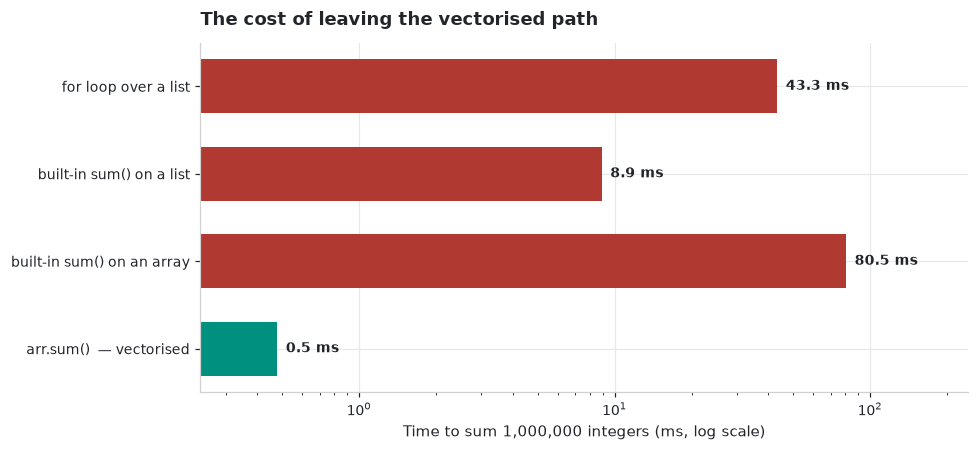

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))

labels = list(timings)
values = [timings[k] * 1000 for k in labels]
# Colour by kind of operation, not by rank: red for the pure-Python paths,
# teal for the vectorised one.
colors = [COLORS["danger"]] * 3 + [COLORS["teal"]]

bars = ax.barh(labels[::-1], values[::-1], color=colors[::-1], height=0.62)

ax.set_xlabel("Time to sum 1,000,000 integers (ms, log scale)")
ax.set_xscale("log")
ax.set_title("The cost of leaving the vectorised path")

for bar, value in zip(bars, values[::-1], strict=True):
    ax.text(value * 1.08, bar.get_y() + bar.get_height() / 2,
            f"{value:.1f} ms", va="center", fontsize=9,
            fontweight="bold", color=COLORS["text"])

ax.set_xlim(min(values) * 0.5, max(values) * 3)
fig.tight_layout()
plt.show()

## 3. What "vectorised" really means

The word gets used loosely. Precisely, it means: **the loop moves out of the
Python interpreter and into compiled code.** Three things follow.

In [7]:
# --- 1. The operation applies to the whole array at once --------------------
a = np.array([1, 2, 3, 4])
b = np.array([10, 20, 30, 40])

print(f"a + b        : {a + b}")
print(f"a * b        : {a * b}         ← element-wise, NOT matrix multiplication")
print(f"a ** 2       : {a ** 2}")
print(f"a > 2        : {a > 2}   ← comparisons vectorise too")

a + b        : [11 22 33 44]
a * b        : [ 10  40  90 160]         ← element-wise, NOT matrix multiplication
a ** 2       : [ 1  4  9 16]
a > 2        : [False False  True  True]   ← comparisons vectorise too


In [8]:
# --- 2. There is no per-element type check ---------------------------------
# The dtype is fixed for the whole array, so the C loop checks it ONCE.
print(f"dtype     : {a.dtype}")
print(f"itemsize  : {a.itemsize} bytes")
print(f"contiguous: {a.flags['C_CONTIGUOUS']}")

dtype     : int64
itemsize  : 8 bytes
contiguous: True


In [9]:
# --- 3. Contiguity lets the CPU work on several values per instruction -----
# Modern CPUs have SIMD registers (AVX2 holds 4 float64s; AVX-512 holds 8).
# They only help when the data sits back to back in memory.
big = np.arange(10_000_000, dtype=np.float64)

contiguous = big
# Every second element: same number of values, but strided access.
strided = big[::2].copy()          # copy so we compare like with like
strided_view = big[::2]            # a view — NOT contiguous

print(f"contiguous copy : {contiguous[:len(strided)].flags['C_CONTIGUOUS']}")
print(f"strided view    : {strided_view.flags['C_CONTIGUOUS']}")

t_contig = time_it(np.sum, strided)
t_strided = time_it(np.sum, strided_view)

print(f"\nsumming {len(strided):,} values")
print(f"  from a contiguous buffer : {t_contig * 1000:6.2f} ms")
print(f"  through a strided view   : {t_strided * 1000:6.2f} ms")
print(f"  → contiguous is {t_strided / t_contig:.1f}× faster")

contiguous copy : True
strided view    : False

summing 5,000,000 values
  from a contiguous buffer :   2.56 ms
  through a strided view   :   5.79 ms
  → contiguous is 2.3× faster


> [!TIP]
> That last result is why `np.ascontiguousarray` exists, and why Module 02's
> notebook 08 spends time on strides. When an array has been sliced, transposed,
> or reshaped, it may no longer be contiguous — and the cost is real.

## 4. Universal functions (ufuncs)

A **ufunc** is a function that operates element-wise on arrays, with
broadcasting, type promotion, and an optional output buffer — all handled for
you. Nearly everything in NumPy is one.

In [10]:
values = np.array([1.0, 4.0, 9.0, 16.0])

print(f"np.sqrt   : {np.sqrt(values)}")
print(f"np.log    : {np.log(values).round(3)}")
print(f"np.exp    : {np.exp([0, 1, 2]).round(3)}")
print(f"np.maximum: {np.maximum([1, 5, 3], [4, 2, 6])}   ← element-wise pairwise max")

print(f"\nis np.sqrt a ufunc? {isinstance(np.sqrt, np.ufunc)}")
print(f"how many ufuncs ship with NumPy? "
      f"{sum(isinstance(getattr(np, name, None), np.ufunc) for name in dir(np))}")

np.sqrt   : [1. 2. 3. 4.]
np.log    : [0.    1.386 2.197 2.773]
np.exp    : [1.    2.718 7.389]
np.maximum: [4 5 6]   ← element-wise pairwise max

is np.sqrt a ufunc? True


how many ufuncs ship with NumPy? 106


### Why `math.sqrt` is not a substitute

The `math` module works on one scalar at a time. Applying it to an array means
looping in Python — exactly the thing we are trying to avoid.

In [11]:
import math

data = np.random.default_rng(42).random(1_000_000) * 100

t_math = time_it(lambda x: [math.sqrt(v) for v in x], data)
t_numpy = time_it(np.sqrt, data)

print(f"[math.sqrt(v) for v in arr] : {t_math * 1000:7.2f} ms")
print(f"np.sqrt(arr)                : {t_numpy * 1000:7.2f} ms")
print(f"→ {t_math / t_numpy:.0f}× faster")

[math.sqrt(v) for v in arr] :  191.39 ms
np.sqrt(arr)                :    3.57 ms
→ 54× faster


### The `out=` parameter — avoiding an allocation

Every ufunc can write into an existing array instead of allocating a new one.
On large arrays in a loop, this matters.

In [12]:
size = 5_000_000
x = np.random.default_rng(0).random(size)
buffer = np.empty(size)

def allocating(arr):
    return np.sqrt(arr)

def reusing(arr, out):
    np.sqrt(arr, out=out)      # writes in place, allocates nothing
    return out

t_alloc = time_it(allocating, x)
t_reuse = time_it(reusing, x, buffer)

print(f"np.sqrt(x)            : {t_alloc * 1000:6.2f} ms  (allocates {format_bytes(x.nbytes)})")
print(f"np.sqrt(x, out=buffer): {t_reuse * 1000:6.2f} ms  (allocates nothing)")
print(f"same result : {np.allclose(allocating(x), reusing(x, buffer))}")

np.sqrt(x)            :  16.57 ms  (allocates 38.1 MiB)
np.sqrt(x, out=buffer):  14.53 ms  (allocates nothing)
same result : True


## 5. How the advantage scales

The gap is not a fixed multiplier — it widens with array size, because the
per-element interpreter overhead is constant while NumPy amortises its own
fixed cost over more data.

In [13]:
sizes = [100, 1_000, 10_000, 100_000, 1_000_000]

loop_times, numpy_times = [], []

for size in sizes:
    arr = np.arange(size, dtype=np.float64)
    lst = arr.tolist()

    loop_times.append(time_it(lambda values: [v * 2 + 1 for v in values], lst))
    numpy_times.append(time_it(lambda a: a * 2 + 1, arr))

print(f"{'n':>10}  {'list comp':>12}  {'numpy':>12}  {'speed-up':>10}")
for size, lt, nt in zip(sizes, loop_times, numpy_times, strict=True):
    print(f"{size:>10,}  {lt * 1e6:>10.1f} µs  {nt * 1e6:>10.1f} µs  "
          f"{lt / nt:>9.1f}×")

         n     list comp         numpy    speed-up
       100         8.2 µs         3.4 µs        2.4×
     1,000        78.9 µs        18.1 µs        4.4×
    10,000       769.1 µs        33.3 µs       23.1×
   100,000      9236.7 µs        99.4 µs       92.9×
 1,000,000    103292.9 µs      3149.6 µs       32.8×


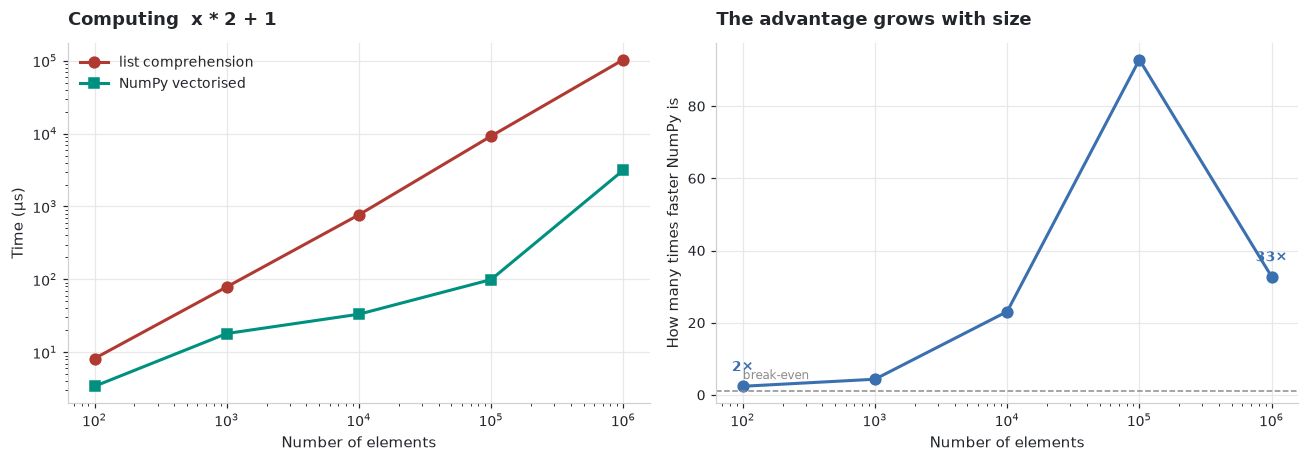

In [14]:
fig, (ax_time, ax_gap) = plt.subplots(1, 2, figsize=(12, 4.3))

# --- Left: absolute times --------------------------------------------------
ax_time.plot(sizes, np.array(loop_times) * 1e6, marker="o",
             label="list comprehension", color=COLORS["danger"])
ax_time.plot(sizes, np.array(numpy_times) * 1e6, marker="s",
             label="NumPy vectorised", color=COLORS["teal"])
ax_time.set_xscale("log")
ax_time.set_yscale("log")
ax_time.set_xlabel("Number of elements")
ax_time.set_ylabel("Time (µs)")
ax_time.set_title("Computing  x * 2 + 1")
ax_time.legend()

# --- Right: the speed-up ratio ---------------------------------------------
speedup = np.array(loop_times) / np.array(numpy_times)
ax_gap.plot(sizes, speedup, marker="o", color=COLORS["primary"])
ax_gap.set_xscale("log")
ax_gap.set_xlabel("Number of elements")
ax_gap.set_ylabel("How many times faster NumPy is")
ax_gap.set_title("The advantage grows with size")
ax_gap.axhline(1, color=COLORS["muted"], linestyle="--", linewidth=1)
ax_gap.annotate("break-even", xy=(sizes[0], 1), xytext=(0, 8),
                textcoords="offset points", fontsize=8, color=COLORS["muted"])

for size, value in zip(sizes, speedup, strict=True):
    if size in (sizes[0], sizes[-1]):
        ax_gap.annotate(f"{value:.0f}×", xy=(size, value), xytext=(0, 10),
                        textcoords="offset points", ha="center",
                        fontsize=9, fontweight="bold", color=COLORS["primary"])

fig.tight_layout()
plt.show()

> [!NOTE]
> At very small sizes the advantage shrinks, and can invert. NumPy pays a fixed
> cost per *call* — argument parsing, dtype resolution, allocation — which a
> plain Python operation avoids. For a handful of values, plain Python can win.
> This is a real effect, not a rounding artefact, and it is why you should not
> "NumPy-ify" a three-element list.

## 6. When NumPy is not the answer

Being honest about the limits is part of knowing the tool:

| Situation | Why NumPy struggles | Reach for |
| :--- | :--- | :--- |
| Heterogeneous columns (strings + numbers + dates) | One dtype per array | **pandas** (Module 03) |
| Genuinely variable-length records | Rectangular arrays only | lists of dicts, or Arrow |
| Data larger than RAM | Everything is in memory | **Dask / Spark** (Module 20) |
| Heavy text processing | No string vectorisation worth the name | Python `str`, or pandas `.str` |
| An algorithm that cannot be expressed without a loop | Python loop overhead returns | **Numba**, **Cython**, or C |
| Fewer than ~100 elements | Per-call overhead dominates | plain Python |

In [15]:
# NumPy CAN hold strings and mixed data — but notice what happens to the dtype.
mixed = np.array([1, "two", 3.0])
print(f"mixed array dtype : {mixed.dtype}   ← everything became a string")
print(f"values            : {mixed}")
print(f"\n1 + 1 gives       : {mixed[0] + mixed[0]!r}   ← string concatenation!")
print("\nThis silently destroys your numbers. It is exactly the problem pandas solves.")

mixed array dtype : <U32   ← everything became a string
values            : ['1' 'two' '3.0']

1 + 1 gives       : '11'   ← string concatenation!

This silently destroys your numbers. It is exactly the problem pandas solves.


## 7. Exercises

### Exercise 1.1 — Measure it yourself

Compare four ways of computing the element-wise product of two sequences of one
million floats: a `for` loop, a list comprehension, `zip` + comprehension, and
`arr_a * arr_b`. Report each time and the speed-up over the slowest.

### Exercise 1.2 — The honest memory question

Write `true_list_size(lst)` returning the total bytes a list of numbers really
occupies (the pointer array plus every referenced object). Compare it with the
equivalent `int64` array for 10, 1 000, and 100 000 elements. Plot the ratio.

### Exercise 1.3 — Find the break-even point

For `x * 2 + 1`, find the array size at which NumPy overtakes a list
comprehension. Search sizes from 1 to 10 000. Why is it not 1?

### Exercise 1.4 — Spot the de-vectorisation

Each of these silently drops back to Python-speed. Explain why, and rewrite it:

```python
# (a)
total = sum(arr)

# (b)
result = np.array([np.sqrt(v) for v in arr])

# (c)
biggest = max(arr)

# (d)
doubled = np.array(list(map(lambda x: x * 2, arr)))
```

### Exercise 1.5 — `out=` in a loop

Simulate an iterative computation: 100 rounds of `y = sqrt(x) + log1p(x)` over a
1-million-element array. Write it once allocating fresh arrays each round, and
once reusing preallocated buffers. Measure both.

## Key takeaways

- A list stores **pointers to objects**; an ndarray stores **raw values, back to
  back, all one dtype**. Every performance difference follows from that.
- **`sys.getsizeof` is shallow** and understates a list badly. `ndarray.nbytes`
  is exact.
- "**Vectorised**" means the loop runs in compiled C, not in the interpreter.
- **Never apply a Python built-in to an array** — `sum(arr)` and `max(arr)` are
  slower than the list versions, because NumPy must box every value.
- Ufuncs accept **`out=`** to reuse a buffer instead of allocating.
- The advantage **grows with array size** and can invert below ~100 elements.
- NumPy needs one dtype and a rectangular shape. When your data is not like
  that, the answer is pandas, not a cleverer array.

---

**Next:** [02 · ndarray Fundamentals](02_ndarray_fundamentals.ipynb) — creation,
shape, indexing, and the views-versus-copies rule that reverses everything you
learned about slicing in Module 01.